In [1]:
import warnings
warnings.filterwarnings('ignore', message='Function stable_cumsum is deprecated')
import pandas as pd
import joblib

test_df = pd.read_parquet('../data/test.parquet')
feature_cols = [c for c in test_df.columns if c not in ['visit', 'treatment_flag', 'spend']]
X_test, y_test, t_test = test_df[feature_cols], test_df['visit'], test_df['treatment_flag']

t_learner = joblib.load('../models/t_learner.pkl')
s_learner = joblib.load('../models/s_learner.pkl')

uplift_t = t_learner.predict(X_test)
uplift_s = s_learner.predict(X_test)
print(X_test.shape)

(12808, 11)


In [2]:
from sklift.metrics import qini_auc_score, uplift_auc_score, weighted_average_uplift

scores = {}
for name, uplift in [('T-Learner', uplift_t), ('S-Learner', uplift_s)]:
    scores[name] = qini_auc_score(y_test, uplift, t_test)
    print(name,
          qini_auc_score(y_test, uplift, t_test),
          uplift_auc_score(y_test, uplift, t_test),
          weighted_average_uplift(y_test, uplift, t_test))

T-Learner 0.017978585218022886 0.008039039519838451 0.035487016517508116
S-Learner 0.04517520314433235 0.020047738293038127 0.035460460204441394


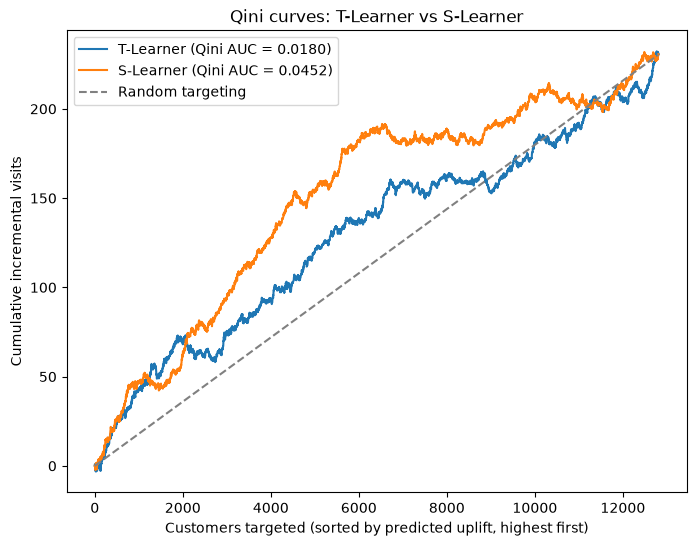

In [3]:
import matplotlib.pyplot as plt
from sklift.metrics import qini_curve

fig, ax = plt.subplots(figsize=(8, 6))
for name, uplift in [('T-Learner', uplift_t), ('S-Learner', uplift_s)]:
    x, y = qini_curve(y_test, uplift, t_test)
    ax.plot(x, y, label=f"{name} (Qini AUC = {scores[name]:.4f})")
ax.plot(x, x * y[-1] / len(y_test), '--', color='grey', label='Random targeting')
ax.set_xlabel('Customers targeted (sorted by predicted uplift, highest first)')
ax.set_ylabel('Cumulative incremental visits')
ax.set_title('Qini curves: T-Learner vs S-Learner')
ax.legend()
plt.show()

In [4]:
import joblib

winner_name = max(scores, key=scores.get)
winning_model = t_learner if winner_name == 'T-Learner' else s_learner
winning_uplift = uplift_t if winner_name == 'T-Learner' else uplift_s

joblib.dump(winning_model, '../models/winning_uplift_model.pkl')
with open('../models/winning_model_name.txt', 'w') as f:
    f.write(winner_name)

print(f"Winner: {winner_name} (Qini AUC = {scores[winner_name]:.4f})")

Winner: S-Learner (Qini AUC = 0.0452)


**Model comparison.** Both models beat random targeting (Qini AUC > 0), but the S-Learner ranks customers clearly better: Qini AUC 0.045 vs. 0.018 for the T-Learner, and AUUC 0.020 vs. 0.008, roughly 2.5× on both. Weighted average uplift is 0.0355 for both; that metric is just the overall observed lift in the test set and does not depend on how customers are ranked, so it cannot separate the models. **Winner: S-Learner.**

This resolves the question left open previously. The S-Learner's predictions were narrower (max 0.57 vs. 0.78, 19% vs. 30% negative), which could have meant either denoising or shrinking real signal. Qini AUC is a ranking metric, so it is unaffected by how wide the predictions are; what it shows is that the S-Learner's ordering of customers is more reliable, consistent with the T-Learner's extreme predictions being mostly estimation noise. A plausible mechanism is that the T-Learner fits two independent models on roughly half the data each and subtracts them, compounding their errors, while the S-Learner shares information across both arms in a single model. Absolute scores are low for both, which is common in uplift problems where the average effect (~4–5pp) is small relative to everything else driving visits, and this comes from a single 12,808-customer test split, so the size of the gap is indicative rather than precise.

On the Qini plot, the S-Learner's curve sits above the random-targeting line across nearly the whole range, with its largest advantage when targeting roughly the top half of customers (about 190 of ~230 total incremental visits captured by ~6,000 customers, versus ~108 expected at random). The T-Learner's curve is above random for most of the range but falls to roughly the random line near 9,000 customers. Both curves are jagged because the test split is small.